# Pre-commit Hooks & Code Review

Automated checks are cheapest when they run before code leaves your computer. **Git hooks** run scripts at points of the Git workflow, for example before a commit is created. The **pre-commit** framework manages these hooks. **Code review** then focuses on what tools cannot check: design, correctness and clarity.

**After this lesson you can:**

1. Write a Git hook that blocks a commit.
2. Configure the pre-commit framework with Ruff and standard checks.
3. Enforce a commit-message convention (Conventional Commits).
4. Review a pull request with a checklist and give useful comments.

In [1]:
import os
import subprocess
import tempfile
from pathlib import Path

# Use a neutral identity and ignore your personal Git configuration, so the output is the same on every machine.
os.environ.update({"GIT_CONFIG_GLOBAL": os.devnull, "GIT_CONFIG_NOSYSTEM": "1",
                   "GIT_AUTHOR_NAME": "Ayse", "GIT_AUTHOR_EMAIL": "ayse@example.com",
                   "GIT_COMMITTER_NAME": "Ayse", "GIT_COMMITTER_EMAIL": "ayse@example.com"})
WORK = Path(tempfile.mkdtemp())

class Output(str):
    """The text output of a command; the notebook does not display it a second time."""
    def _ipython_display_(self):
        pass

def short(text: str) -> str:
    return text.replace(str(WORK), "<work>").replace(str(Path.cwd().parent), "<repo>")

def sh(cmd: str, cwd: Path = WORK, env: dict | None = None, quiet: bool = False) -> Output:
    """Run a shell command, print it and its output (temporary paths shortened)."""
    r = subprocess.run(["bash", "-c", cmd], cwd=cwd, capture_output=True, text=True, env={**os.environ, **(env or {})})
    out = short((r.stdout + r.stderr).strip())
    if not quiet:
        print(f"$ {short(cmd)}" + (f"\n{out}" if out else ""))
    return Output(r.stdout)

## 1. Git Hooks

Git runs executable files in `.git/hooks/` at fixed points:

| Hook | Runs | A non-zero exit code |
| :--- | :--- | :--- |
| `pre-commit` | before the commit is created | aborts the commit |
| `commit-msg` | after the message is written | aborts the commit |
| `pre-push` | before `git push` | aborts the push |

The hook below blocks commits that contain something that looks like a secret key.

In [2]:
repo = WORK / "service"
repo.mkdir()
sh("git init -q -b main", repo)
hook = repo / ".git" / "hooks" / "pre-commit"
hook.write_text(r"""#!/bin/bash
# Block commits that add strings that look like API keys or private keys.
if git diff --cached -U0 | grep -E '^\+.*(sk-[A-Za-z0-9]{20,}|AKIA[0-9A-Z]{16}|BEGIN (RSA|OPENSSH) PRIVATE KEY)'; then
  echo "pre-commit: possible secret found. Remove it and use an environment variable." >&2
  exit 1
fi
""")
hook.chmod(0o755)

(repo / "client.py").write_text('API_KEY = "sk-abcdefghijklmnopqrstuvwxyz123456"\n')
sh("git add client.py && git commit -m 'Add client'; echo exit code: $?", repo)
(repo / "client.py").write_text('import os\nAPI_KEY = os.environ["API_KEY"]\n')
sh("git add client.py && git commit -q -m 'Add client' && git log --oneline", repo)

$ git init -q -b main
$ git add client.py && git commit -m 'Add client'; echo exit code: $?
exit code: 1
+API_KEY = "sk-abcdefghijklmnopqrstuvwxyz123456"
pre-commit: possible secret found. Remove it and use an environment variable.
$ git add client.py && git commit -q -m 'Add client' && git log --oneline
24d839c Add client


## 2. The pre-commit Framework

Hand-written hooks live only in your `.git` folder; your teammates do not get them. The **pre-commit** framework stores the hook configuration in the repository (`.pre-commit-config.yaml`), so every developer runs the same checks. It also runs the same checks in CI.

The configuration below uses `repo: local` hooks: they run tools that are already installed in the course environment, so no extra download is needed. Most projects instead reference published hook repositories, for example `https://github.com/astral-sh/ruff-pre-commit`.

In [3]:
import sys

venv_bin = Path(sys.executable).parent
(repo / "check_size.sh").write_text('for f in "$@"; do if [ "$(stat -c%s "$f")" -gt 512000 ]; then echo "too large: $f"; exit 1; fi; done\n')
(repo / ".pre-commit-config.yaml").write_text(f"""
repos:
  - repo: local
    hooks:
      - id: ruff-check
        name: ruff check (lint + autofix)
        entry: {venv_bin}/ruff check --fix --exit-non-zero-on-fix
        language: system
        types: [python]
      - id: ruff-format
        name: ruff format
        entry: {venv_bin}/ruff format
        language: system
        types: [python]
      - id: no-large-files
        name: block files larger than 500 kB
        entry: bash check_size.sh
        language: system
""")
sh(f"{venv_bin}/pre-commit install --hook-type pre-commit 2>&1 | sed 's|{venv_bin}/||'", repo)
(repo / "report.py").write_text("import os, sys\ndef total( xs ):\n  return sum(xs)\n")
sh("git add -A && git commit -q -m 'Add report'; echo exit code: $?", repo)

$ <repo>/.venv/bin/pre-commit install --hook-type pre-commit 2>&1 | sed 's|<repo>/.venv/bin/||'
Running in migration mode with existing hooks at .git/hooks/pre-commit.legacy
Use -f to use only pre-commit.
pre-commit installed at .git/hooks/pre-commit


$ git add -A && git commit -q -m 'Add report'; echo exit code: $?
exit code: 1
ruff check (lint + autofix)..............................................Failed
- hook id: ruff-check
- exit code: 1
- files were modified by this hook

Found 2 errors (2 fixed, 0 remaining).

ruff format..............................................................Failed
- hook id: ruff-format
- files were modified by this hook

1 file reformatted

block files larger than 500 kB...........................................Passed


pre-commit kept the hand-written secret hook from Section 1 as `pre-commit.legacy` and still runs it ("migration mode"). The hooks found problems: Ruff removed the unused imports and reformatted the file, and the commit was aborted because the files changed. The developer reviews the changes, stages them and commits again:

In [4]:
print((repo / "report.py").read_text())
sh("git add -A && git commit -q -m 'Add report' && git log --oneline", repo)

def total(xs):
    return sum(xs)



$ git add -A && git commit -q -m 'Add report' && git log --oneline
4cb57c0 Add report
24d839c Add client
ruff check (lint + autofix)..............................................Passed
ruff format..............................................................Passed
block files larger than 500 kB...........................................Passed


## 3. Commit-Message Convention

**Conventional Commits** give commit messages a fixed structure: `type(scope): summary`, with types such as `feat`, `fix`, `docs`, `refactor`, `test`, `chore`. Tools then generate changelogs and version numbers automatically. A `commit-msg` hook can enforce the format.

In [5]:
msg_hook = repo / ".git" / "hooks" / "commit-msg"
msg_hook.write_text(r"""#!/bin/bash
pattern='^(feat|fix|docs|refactor|test|chore|perf|ci)(\([a-z0-9-]+\))?!?: .{1,72}$'
if ! head -1 "$1" | grep -qE "$pattern"; then
  echo "commit-msg: use 'type(scope): summary', e.g. 'fix(api): handle empty input'" >&2
  exit 1
fi
""")
msg_hook.chmod(0o755)

attempts = ["updated stuff", "fix(report): handle empty input", "feat: add CSV export", "Feat: Add things!!"]
results = {}
for i, msg in enumerate(attempts):
    (repo / f"note_{i}.txt").write_text(msg)
    r = subprocess.run(["bash", "-c", f"git add -A && git commit -q -m '{msg}'"], cwd=repo, capture_output=True, text=True)
    results[msg] = "accepted" if r.returncode == 0 else "rejected"
    print(f"{results[msg]:<9} {msg!r}")
sh("git log --oneline", repo)

rejected  'updated stuff'


accepted  'fix(report): handle empty input'


accepted  'feat: add CSV export'


rejected  'Feat: Add things!!'
$ git log --oneline
8fcd11c feat: add CSV export
2bdd0f9 fix(report): handle empty input
4cb57c0 Add report
24d839c Add client


## 4. Where Checks Run

The same check can run in three places. The earlier it runs, the cheaper a failure is:

| Place | Feedback time | Who sees a failure |
| :--- | :--- | :--- |
| editor (Ruff extension) | instant | only you |
| pre-commit hook | seconds | only you |
| CI on the pull request (M34) | minutes | the whole team |

The plot shows the outcome of the commit attempts in this lesson.

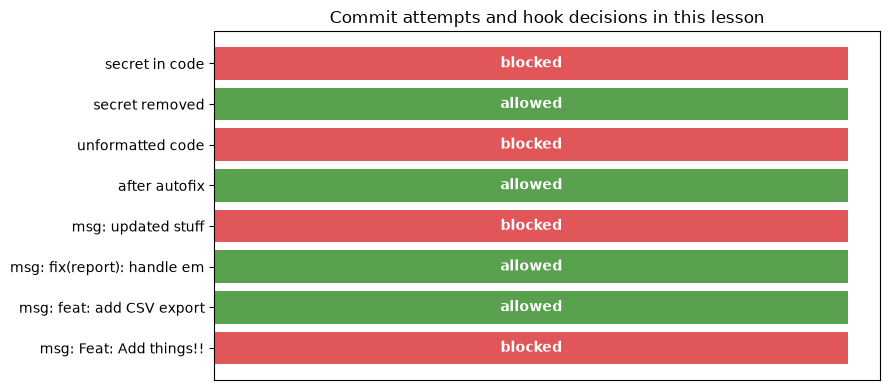

In [6]:
import matplotlib.pyplot as plt

outcomes = {"secret in code": "blocked", "secret removed": "allowed", "unformatted code": "blocked",
            "after autofix": "allowed"}
outcomes.update({f"msg: {m[:22]}": ("allowed" if r == "accepted" else "blocked") for m, r in results.items()})
fig, ax = plt.subplots(figsize=(9, 4))
names = list(outcomes)
ax.barh(names, [1] * len(names), color=["#59A14F" if v == "allowed" else "#E15759" for v in outcomes.values()])
for i, v in enumerate(outcomes.values()):
    ax.text(0.5, i, v, ha="center", va="center", color="white", fontweight="bold")
ax.set(title="Commit attempts and hook decisions in this lesson", xticks=[])
ax.invert_yaxis()
plt.tight_layout()
plt.show()

## 5. Code Review

Tools check style and simple bugs. Humans review what tools cannot:

**Checklist for the reviewer**

1. **Purpose:** does the change do what the PR description says? Is the problem worth solving this way?
2. **Correctness:** edge cases, error handling, off-by-one errors, data leaks between train and test sets.
3. **Tests:** is new behaviour tested? Would the tests fail if the code were wrong?
4. **Design:** is the code in the right place? Is there a simpler solution?
5. **Readability:** clear names, small functions, comments that explain *why*.
6. **Security and data:** no secrets, no personal data in logs, inputs validated.

**Good review comments** are specific, explain the reason and separate blocking issues from suggestions:

| Weak comment | Useful comment |
| :--- | :--- |
| "This is wrong." | "`len(xs)` is 0 for an empty list, so line 12 divides by zero. Can we return `None` here and add a test?" |
| "Rename this." | "nit: `d` → `days_since_signup` would make line 30 readable without the comment." |

**For the author:** keep pull requests small (one topic, ideally a few hundred lines), write a description with the *why* and how to test, and respond to every comment.

*Insight: Automate everything that a tool can check (format, lint, secrets, commit messages) with pre-commit and CI, so that human review time goes to design, correctness and tests.*

## Real-World Use Case or Analogy

Pre-commit hooks are like the **metal detector at the entrance of an airport**: a quick automatic check that stops obvious problems before anybody boards. Code review is the **pilot's briefing with the co-pilot**: a human discussion about the plan, the risks and what could go wrong.

In companies, pre-commit and CI catch leaked credentials before they reach GitHub (where bots scan public repositories for keys within minutes). Code review is also how knowledge spreads in a team: every reviewed change is seen by at least two people.